Biblioteki

In [1]:
import json
import cv2
import matplotlib.pyplot as plt
import os
import numpy as np
from torch.utils.data import Dataset, DataLoader
import torch

Wczytanie pliku JSON z adnotacjami COCO

In [2]:
def load_coco_annotations(json_path):
    """
    Wczytuje adnotacje COCO z pliku JSON.

    Parameters
    ----------
    json_path : str
        Ścieżka do pliku JSON.

    Returns
    -------
    dict
        Słownik zawierający dane COCO.
    """

    with open(json_path, "r") as f:
        coco = json.load(f)

    return coco

Wczytanie zdjęcia

In [3]:
def load_image(image_path):
    """
    Wczytuje zdjęcie i konwertuje je z BGR do RGB.

    Parameters
    ----------
    image_path : str
        Ścieżka do zdjęcia.

    Returns
    -------
    np.ndarray
        Obraz w formacie RGB.
    """

    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f"Nie udało się wczytać obrazu: {image_path}"
        )

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    return image

Wczytanie adnotacji danego zdjecia

In [4]:
def load_annotations(coco,image_id):
  """
  Wczytuje adnotacje zdjęcia o podanym ID.

  Parameters
  ----------
  coco : dict
    Słownik zawierający dane COCO.

  image_id : int
    Identyfikator zdjecia.

  Returns
  -------
  list
    Lista adnotacji
  """

  annotations = []

  for annotation in coco["annotations"]:
    if annotation["image_id"] == image_id:
      annotations.append(annotation)

  return annotations

Tworzenie maski do zdjecia na podstawie adnotacji

In [5]:
def create_mask(image_info, annotations):
  """
  Tworzy maskę dla zdjęcia na podstawie adnotacji.

  Parameters
  ----------


  Returns
  -------
  np.ndarray
    Maska zdjęcia.
  """

  # Tlo skladajace sie z zer
  height = image_info["height"]
  width = image_info["width"]

  mask = np.zeros((height, width), dtype=np.uint8) # uint8 - int o wielkosci 8 bitow - 256 wartosci

  # Uzupelnienie maski kategoriami
  for annotation in annotations:

    category_id = annotation["category_id"]

    polygon = np.array(
        annotation["segmentation"][0],
        dtype=np.int32
    )

    polygon = polygon.reshape(-1, 2)

    cv2.fillPoly(
        mask,
        [polygon],
        category_id
    )

  return mask

Wizualizacja maski

In [6]:
def visualize_image_and_mask(image, mask):
    """
    Wyświetla zdjęcie oraz odpowiadającą mu maskę.
    """

    plt.figure(figsize=(12, 6))

    # Oryginalne zdjęcie
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Oryginalne zdjęcie")
    plt.axis("off")

    # Maska
    plt.subplot(1, 2, 2)
    plt.imshow(mask)
    plt.title("Maska")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

Mapowanie nazwy maski do jej id

In [7]:
def category_id_to_name():

  category_id_to_name = {}
  for category in coco["categories"]:
    category_id = category["id"]
    category_name = category["name"]

    category_id_to_name[category_id] = category_name

  category_id_to_name[0] = "background" # zmiana nazwy z Fasion na backgroubd

  return category_id_to_name

In [8]:
def categories_on_photo(mask):

  unique_categories = np.unique(mask)

  for category_id in unique_categories:
    category_name = category_id_to_name()[category_id]
    print(f"{category_id}: {category_name}")

In [9]:
def resize_image_and_mask(image, mask, size=(256, 256)):
    # Zmiana rozmiaru obrazu
    image = cv2.resize(
        image,
        size,
        interpolation=cv2.INTER_LINEAR
    )

    # Zmiana rozmiaru maski
    mask = cv2.resize(
        mask,
        size,
        interpolation=cv2.INTER_NEAREST
    )

    return image, mask

#MAIN

In [10]:
# # Static
# DATASET_PATH = "/content/drive/MyDrive/Colab Notebooks/INZ/dataset/train"
# JSON_PATH = "/content/drive/MyDrive/Colab Notebooks/INZ/dataset/_annotations.coco.json"

# # Wczytanie JSON
# coco = load_coco_annotations(JSON_PATH)

# # Wyswietlenie obrazu
# image_info = coco["images"][0]

# image_path = os.path.join(DATASET_PATH, image_info["file_name"])

# image = load_image(image_path)

# # Adnotacje do obrazu
# annotations = load_annotations(coco,image_info["id"])

# # Tworzenie maski dla obrazu
# mask = create_mask(image_info,annotations)

# # Wyswietlenie maski
# visualize_image_and_mask(image,mask)


In [11]:
# # ==========================================
# # Wyświetlenie wszystkich klas
# # ==========================================

# for category in coco["categories"]:
#     print(
#         f'id: {category["id"]}, '
#         f'name: {category["name"]}'
#     )

In [12]:
# print(category_id_to_name())

In [13]:
# categories_on_photo(mask)

In [14]:
# Klasa Dataset - łącząca wczytywanie w jedno miejsce (source: https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html#)

class ClothesDataset(Dataset):
  def __init__(self):
    self.dataset_path = "/content/drive/MyDrive/Colab Notebooks/INZ/dataset/train"
    self.json_path = "/content/drive/MyDrive/Colab Notebooks/INZ/dataset/_annotations.coco.json"

    self.coco = load_coco_annotations(self.json_path)

  def __len__(self):
    return len(self.coco["images"])

  def __getitem__(self,index):
    # Zdobywanie danych o obrazie
    image_info = self.coco["images"][index]
    image_path = os.path.join(self.dataset_path,image_info["file_name"])
    image = load_image(image_path)

    # Adnotacje do obrazu
    annotations = load_annotations(self.coco,image_info["id"])

    # Tworzenie maski dla obrazu
    mask = create_mask(image_info,annotations)

    # Resize obrazu i maski
    image, mask = resize_image_and_mask(
        image,
        mask
    )

    # Dane wyjsciowe
    image = torch.from_numpy(image) # zamieniamy na tensor

    # Normalizacja skaluje wartości wejściowe obrazu do bardziej odpowiedniego zakresu, co ułatwia i stabilizuje proces uczenia sieci neuronowej
    image = image.float()
    image = image / 255.0

    image = image.permute(2,0,1) # bo np.narray jest H W C, a tensor jest C H W

    # Maska nie jest normalizowana - musza zostac zachowane etykiety
    mask = torch.from_numpy(mask).long() # long do crossentropy

    return image, mask

In [15]:
# # Sprawdzenie klasy dataset
# dataset = ClothesDataset()

# image, mask = dataset[0]

# print("IMAGE")
# print(type(image))
# print(image.shape)
# print(image.dtype)
# print(image.min())
# print(image.max())

# print("\nMASK")
# print(type(mask))
# print(mask.shape)
# print(mask.dtype)
# print(mask.unique())

#U-Net

In [16]:
import torch
import torch.nn as nn

In [17]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels): # in_channels - RGB, out_channels - ile ma zwrocic cech
        super().__init__() # bo dziedziczymy po nn.Module

        self.double_conv = nn.Sequential( #kontener PyTorch, który wykonuje zapisane w nim warstwy po kolei.
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1), #okreslenie kanałów wejściowych, padding=1 to	dodanie jednego piksela obramowania, aby zachować wysokość i szerokość
            nn.ReLU(inplace=True), # relu(x)=max(0,x), inplace może oszczędzać pamięć

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

In [18]:
class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.maxpool_conv = nn.Sequential(
            nn.MaxPool2d(kernel_size=2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.maxpool_conv(x)

In [19]:
class Up(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            in_channels // 2,
            kernel_size=2,
            stride=2
        )

        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)

        # Połączenie cech z encodera i decodera
        x = torch.cat([skip, x], dim=1)

        return self.conv(x)

In [20]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=11):
        super().__init__()

        # Encoder
        self.inc = DoubleConv(in_channels, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)

        # Najgłębsza część sieci
        self.bottleneck = Down(512, 1024)

        # Decoder
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)

        # Warstwa wyjściowa
        self.outc = nn.Conv2d(
            64,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):
        # Encoder - zapamiętujemy cechy do skip connections
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        # Bottleneck
        x5 = self.bottleneck(x4)

        # Decoder - łączymy cechy z encodera
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        # Wynik dla każdej klasy w każdym pikselu
        return self.outc(x)

In [21]:

model = UNet()

# Dwa przykładowe obrazy RGB o rozmiarze 256 x 256
images = torch.randn(2, 3, 256, 256)

# Przepuszczamy obrazy przez sieć
output = model(images)

print("Wejście:", images.shape)
print("Wyjście:", output.shape)


Wejście: torch.Size([2, 3, 256, 256])
Wyjście: torch.Size([2, 11, 256, 256])


Testy

In [22]:
# Testy
dataset = ClothesDataset()

dataloader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=True
)

# for images, masks in dataloader:
#     print("Images:", images.shape)
#     print("Masks:", masks.shape)
#     break


In [23]:
model = UNet(
    in_channels=3,
    num_classes=14
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

In [24]:

# import numpy as np

# all_class_ids = set()

# for i in range(len(dataset)):
#     image, mask = dataset[i]
#     class_ids = np.unique(mask.numpy())

#     all_class_ids.update(class_ids.tolist())

# print("Liczba zdjęć:", len(dataset))
# print("Wszystkie identyfikatory klas:", sorted(all_class_ids))
# print("Największy identyfikator:", max(all_class_ids))


In [25]:

# categories = dataset.coco["categories"]

# print("Liczba kategorii w COCO:", len(categories))
# print("\nKategorie:")

# for category in categories:
#     print(
#         "ID:", category["id"],
#         "| Nazwa:", category["name"]
#     )


In [26]:

import torch

print("Czy CUDA jest dostępna:", torch.cuda.is_available())
print("Urządzenie używane przez model:", next(model.parameters()).device)

if torch.cuda.is_available():
    print("Karta graficzna:", torch.cuda.get_device_name(0))


Czy CUDA jest dostępna: True
Urządzenie używane przez model: cpu
Karta graficzna: Tesla T4


In [27]:
num_epochs = 10

for epoch in range(num_epochs):

    model.train()
    total_loss = 0.0

    for images, masks in dataloader:

        # Przeniesienie danych na GPU lub CPU
        images = images
        masks = masks

        # Wyzerowanie gradientów z poprzedniego kroku
        optimizer.zero_grad()

        # Przewidywanie wyników przez U-Net
        outputs = model(images)

        # Porównanie przewidywań z prawdziwymi maskami
        loss = criterion(outputs, masks)

        # Obliczenie gradientów
        loss.backward()

        # Aktualizacja wag sieci
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(dataloader)

    print(
        f"Epoka {epoch + 1}/{num_epochs}, "
        f"loss: {average_loss:.4f}"
    )


Epoka 1/10, loss: 1.1357
Epoka 2/10, loss: 0.6791
Epoka 3/10, loss: 0.6513
Epoka 4/10, loss: 0.6322
Epoka 5/10, loss: 0.5908
Epoka 6/10, loss: 0.5554
Epoka 7/10, loss: 0.5298
Epoka 8/10, loss: 0.5105
Epoka 9/10, loss: 0.4951
Epoka 10/10, loss: 0.4844


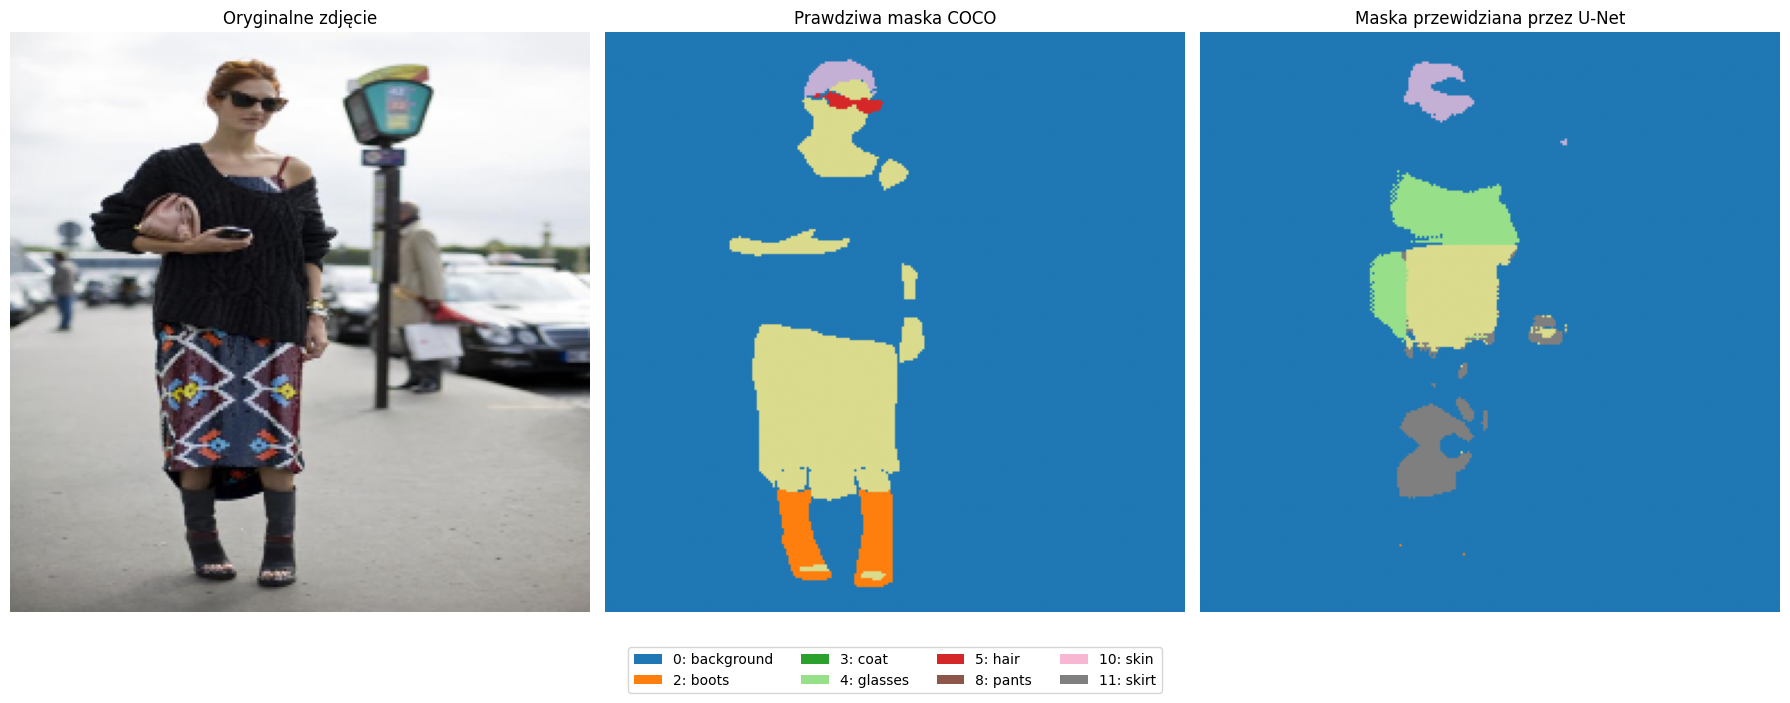

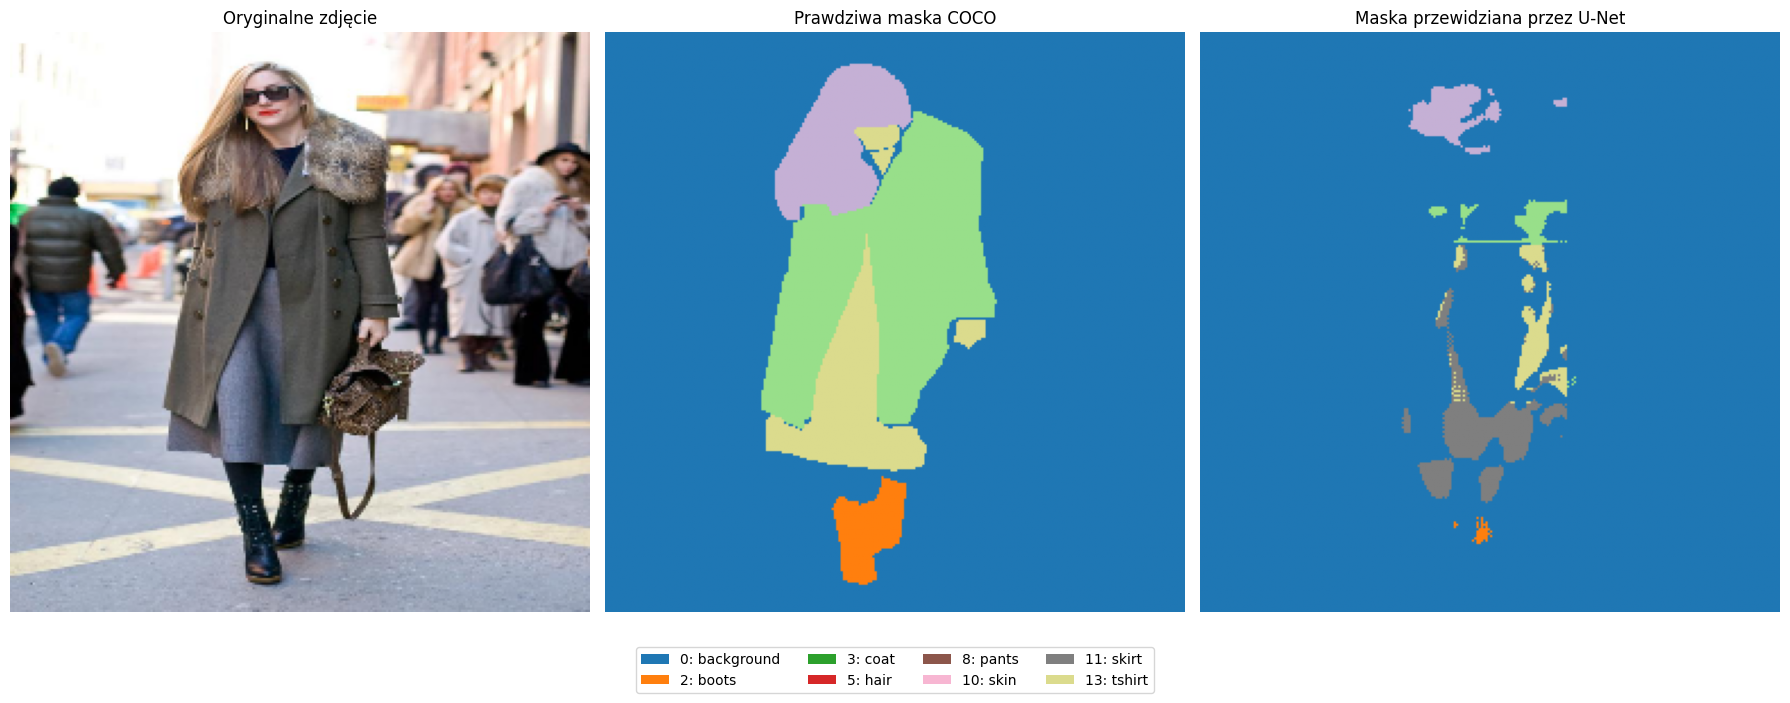

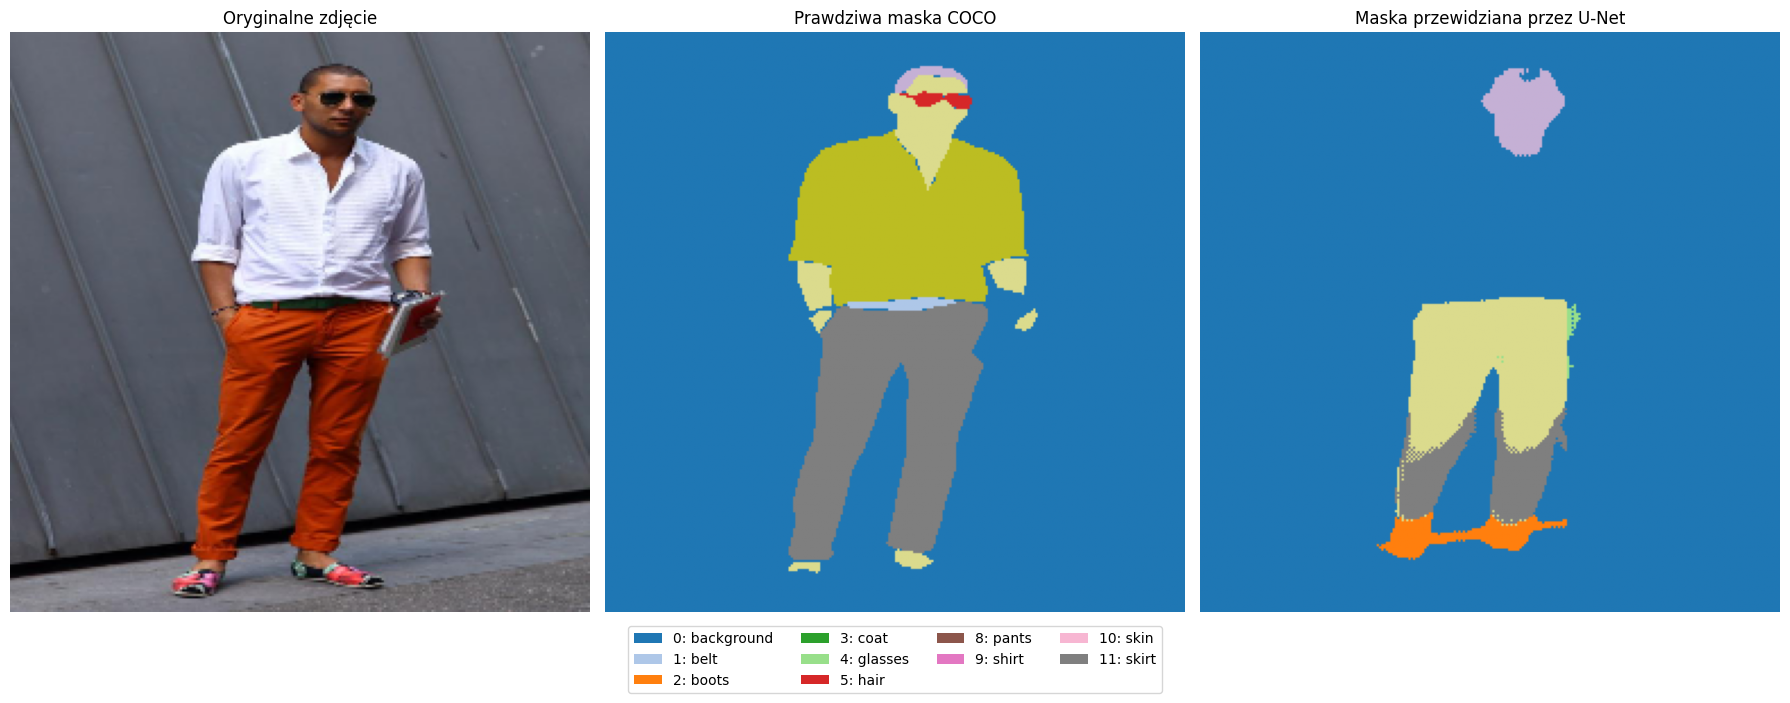

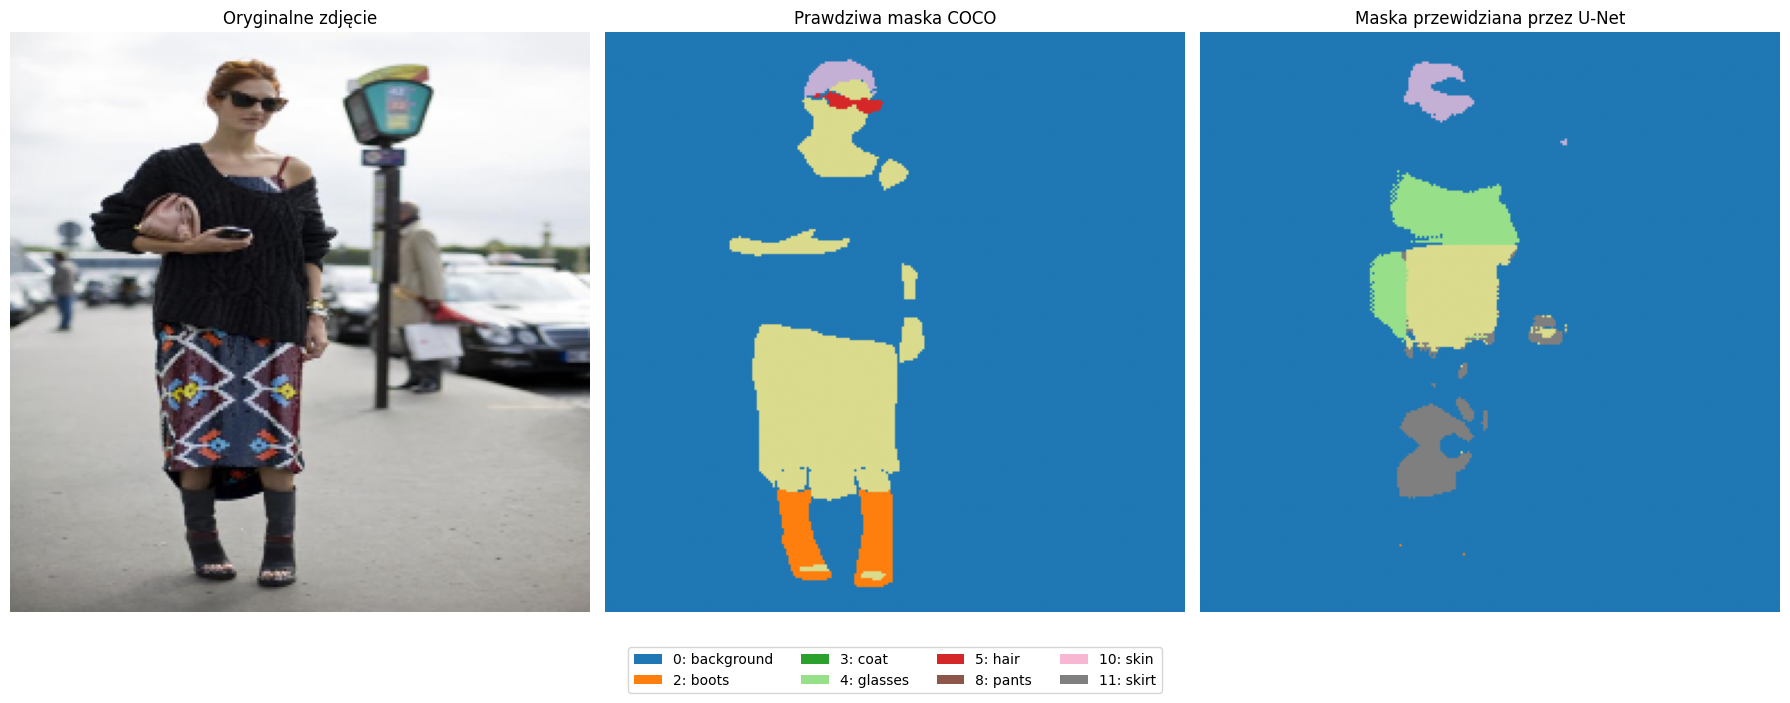

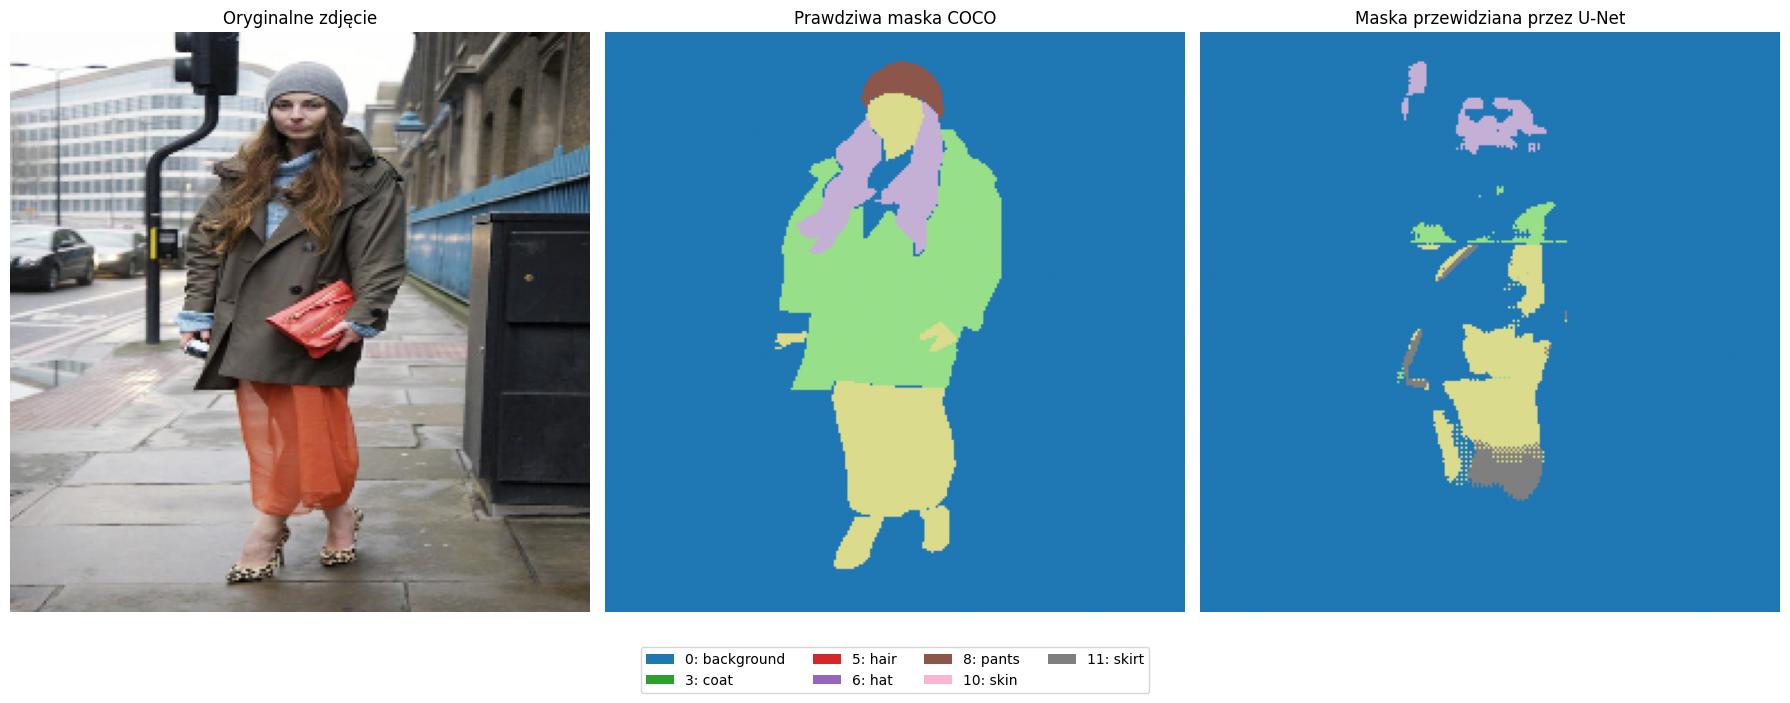

In [32]:

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def show_prediction(dataset, model, index):

    # Pobranie zdjęcia i prawdziwej maski
    image, true_mask = dataset[index]

    # Sieć musi być w trybie ewaluacji
    model.eval()

    with torch.no_grad():

        # Dodajemy wymiar batcha: [C, H, W] -> [1, C, H, W]
        input_image = image.unsqueeze(0)

        # Przewidywanie modelu
        output = model(input_image)

        # Wybieramy klasę z najwyższym wynikiem dla każdego piksela
        predicted_mask = torch.argmax(
            output,
            dim=1
        )[0]

    # Przygotowanie danych do wyświetlenia
    image_np = image.permute(1, 2, 0).cpu().numpy()
    true_mask_np = true_mask.cpu().numpy()
    predicted_mask_np = predicted_mask.cpu().numpy()

    # Nazwy klas z adnotacji COCO
    category_names = {
        category["id"]: category["name"]
        for category in dataset.coco["categories"]
    }
    category_names[0] = "background"

    # Te same kolory klas na obu maskach
    colors = plt.get_cmap("tab20", 16)
    color_list = [colors(i) for i in range(14)]
    cmap = ListedColormap(color_list)

    # Rysowanie wyników
    fig, axes = plt.subplots(1, 3, figsize=(18, 7))

    axes[0].imshow(image_np)
    axes[0].set_title("Oryginalne zdjęcie")

    axes[1].imshow(
        true_mask_np,
        cmap=cmap,
        vmin=0,
        vmax=10
    )
    axes[1].set_title("Prawdziwa maska COCO")

    axes[2].imshow(
        predicted_mask_np,
        cmap=cmap,
        vmin=0,
        vmax=10
    )
    axes[2].set_title("Maska przewidziana przez U-Net")

    for ax in axes:
        ax.axis("off")

    # Legenda obejmuje klasy obecne w prawdziwej
    # masce lub w przewidywaniu modelu
    class_ids = np.union1d(
        np.unique(true_mask_np),
        np.unique(predicted_mask_np)
    )

    legend_items = [
        Patch(
            facecolor=color_list[int(class_id)],
            label=(
                f"{int(class_id)}: "
                f"{category_names.get(int(class_id), 'unknown')}"
            )
        )
        for class_id in class_ids
    ]

    fig.legend(
        handles=legend_items,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, -0.04)
    )

    plt.tight_layout()
    plt.show()


# Pokazujemy pierwsze zdjęcie z datasetu
show_prediction(dataset, model, index=1)
show_prediction(dataset, model, index=15)
show_prediction(dataset, model, index=2)
show_prediction(dataset, model, index=1)
show_prediction(dataset, model, index=8)


sprawdzenie bledu

Liczba zdjęć w zbiorze: 273

Kształt wyjścia sieci: torch.Size([1, 14, 256, 256])

--- PRAWDZIWA MASKA ---
Klasa 0: 51647 pikseli (78.81%)
Klasa 1: 179 pikseli (0.27%)
Klasa 4: 136 pikseli (0.21%)
Klasa 5: 146 pikseli (0.22%)
Klasa 8: 5845 pikseli (8.92%)
Klasa 9: 5971 pikseli (9.11%)
Klasa 10: 1612 pikseli (2.46%)

--- MASKA PRZEWIDZIANA PRZEZ MODEL ---
Klasa 0: 58296 pikseli (88.95%)
Klasa 2: 699 pikseli (1.07%)
Klasa 3: 65 pikseli (0.10%)
Klasa 5: 931 pikseli (1.42%)
Klasa 8: 1626 pikseli (2.48%)
Klasa 11: 3919 pikseli (5.98%)


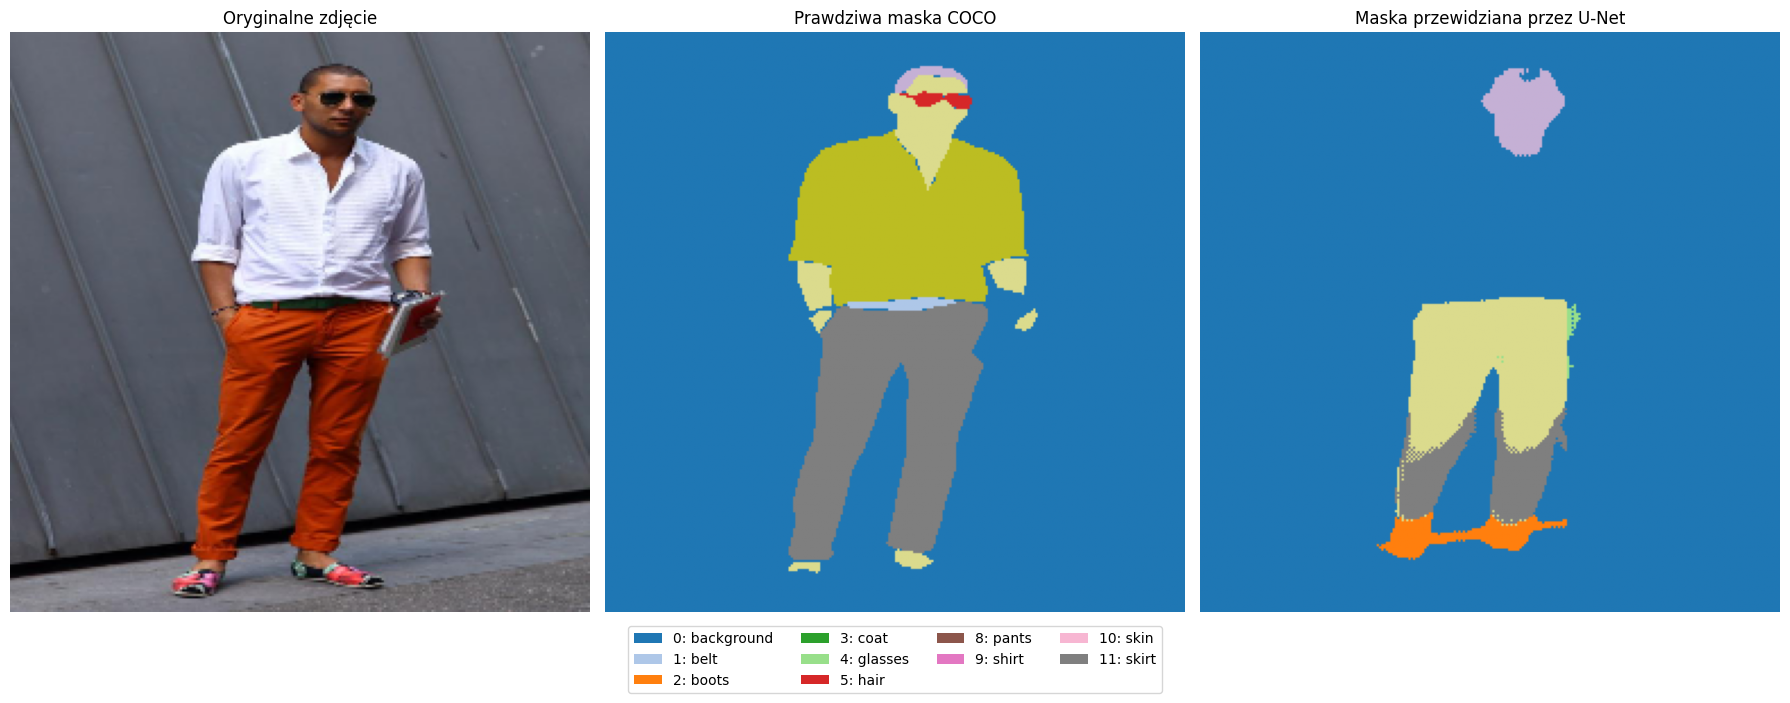

In [37]:

import torch

# Ustawiamy model w tryb przewidywania
model.eval()

# Sprawdzamy, ile zdjęć znajduje się w zbiorze
print("Liczba zdjęć w zbiorze:", len(dataset))

# Pobieramy pierwsze zdjęcie i jego prawdziwą maskę
image, true_mask = dataset[2]

# Model przewiduje klasy pikseli
with torch.no_grad():
    input_image = image.unsqueeze(0)
    outputs = model(input_image)
    predicted_mask = outputs.argmax(dim=1)[0].cpu()

# Wypisujemy kształt wyjścia sieci
print("\nKształt wyjścia sieci:", outputs.shape)

# Sprawdzamy, jakie klasy występują w prawdziwej masce
true_ids, true_counts = torch.unique(
    true_mask, return_counts=True
)

print("\n--- PRAWDZIWA MASKA ---")
for class_id, count in zip(
    true_ids.tolist(), true_counts.tolist()
):
    percentage = 100 * count / true_mask.numel()
    print(
        f"Klasa {class_id}: {count} pikseli "
        f"({percentage:.2f}%)"
    )

# Sprawdzamy, jakie klasy przewidział model
pred_ids, pred_counts = torch.unique(
    predicted_mask, return_counts=True
)

print("\n--- MASKA PRZEWIDZIANA PRZEZ MODEL ---")
for class_id, count in zip(
    pred_ids.tolist(), pred_counts.tolist()
):
    percentage = 100 * count / predicted_mask.numel()
    print(
        f"Klasa {class_id}: {count} pikseli "
        f"({percentage:.2f}%)"
    )

show_prediction(dataset, model, index=2)


In [38]:

import torch

# Liczba klas w modelu: klasy 0–10
num_classes = 13

# Dla każdej klasy zliczamy liczbę pikseli
class_pixel_counts = torch.zeros(
    num_classes, dtype=torch.long
)

for image, mask in dataset:
    pixel_counts = torch.bincount(
        mask.flatten(),
        minlength=num_classes
    )

    class_pixel_counts += pixel_counts[:num_classes]

# Obliczamy liczbę wszystkich pikseli
total_pixels = class_pixel_counts.sum().item()

print("--- UDZIAŁ PIKSELI KLAS W CAŁYM ZBIORZE ---")
print("Liczba zdjęć:", len(dataset))
print("Liczba wszystkich pikseli:", total_pixels)

for class_id, count in enumerate(
    class_pixel_counts.tolist()
):
    percentage = 100 * count / total_pixels
    print(
        f"Klasa {class_id}: {count} pikseli "
        f"({percentage:.2f}%)"
    )


--- UDZIAŁ PIKSELI KLAS W CAŁYM ZBIORZE ---
Liczba zdjęć: 273
Liczba wszystkich pikseli: 17662801
Klasa 0: 14626557 pikseli (82.81%)
Klasa 1: 20508 pikseli (0.12%)
Klasa 2: 85594 pikseli (0.48%)
Klasa 3: 689277 pikseli (3.90%)
Klasa 4: 12381 pikseli (0.07%)
Klasa 5: 270306 pikseli (1.53%)
Klasa 6: 15304 pikseli (0.09%)
Klasa 7: 176287 pikseli (1.00%)
Klasa 8: 653291 pikseli (3.70%)
Klasa 9: 239351 pikseli (1.36%)
Klasa 10: 449506 pikseli (2.54%)
Klasa 11: 415493 pikseli (2.35%)
Klasa 12: 8946 pikseli (0.05%)
